# Data Management for Machine Learning – Assignment 2

## End-to-End Data Management Pipeline for a Recommendation System

**Submitted by:** Putta Madhu Rani  
**Roll Number:** 2025AG05144

**Project:** E-commerce Recommendation System  
**Environment:** Google Colab  
**Programming Language:** Python  
**Libraries:** Pandas, NumPy, Scikit-learn, Matplotlib, Seaborn and MLflow

### Objective
To design and implement an end-to-end data management pipeline that includes data ingestion, validation, preparation, transformation, feature management, model training, model evaluation and workflow orchestration.

In [1]:
# Step 1: Install required Python libraries

!pip install -q pandas numpy scikit-learn matplotlib seaborn mlflow

In [2]:
# Step 2: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os
import json
import warnings

from datetime import datetime

warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 100)

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# Step 3: Create project directories

project_path = "/content/DM4ML_Recommendation_System"

folders = [
    "data/raw",
    "data/processed",
    "data/features",
    "data/errors",
    "src/ingestion",
    "src/validation",
    "src/preparation",
    "src/transformation",
    "src/features",
    "src/training",
    "src/evaluation",
    "models",
    "reports",
    "experiments",
    "configs"
]

for folder in folders:
    os.makedirs(os.path.join(project_path, folder), exist_ok=True)

# Create README file
readme_path = os.path.join(project_path, "README.md")

with open(readme_path, "w") as file:
    file.write("# DM4ML Recommendation System\n")
    file.write("End-to-End Data Management Pipeline\n")

print("Project folder structure created successfully!")
print("Location:", project_path)

Project folder structure created successfully!
Location: /content/DM4ML_Recommendation_System


In [4]:
# Step 4: Verify project setup

print("Python version:", os.sys.version)

print("Pandas version:", pd.__version__)

print("NumPy version:", np.__version__)

print("\nProject directory exists:",
      os.path.exists(project_path))

print("\nProject folders:")
for item in os.listdir(project_path):
    print("-", item)

Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Pandas version: 2.2.3
NumPy version: 2.4.6

Project directory exists: True

Project folders:
- README.md
- data
- src
- configs
- experiments
- reports
- models


In [5]:
# ==========================================
# STEP 2: DATA INGESTION
# ==========================================

import pandas as pd
import numpy as np
import os

# Set random seed for reproducible data
np.random.seed(42)

# Project data folders
raw_data_path = os.path.join(project_path, "data", "raw")

# ------------------------------------------
# 1. CREATE USERS DATASET
# ------------------------------------------

num_users = 500

users = pd.DataFrame({
    "user_id": range(1, num_users + 1),
    "age": np.random.randint(18, 60, num_users),
    "gender": np.random.choice(["Male", "Female"], num_users),
    "location": np.random.choice(
        ["Bangalore", "Hyderabad", "Chennai", "Mumbai", "Delhi"],
        num_users
    )
})

# ------------------------------------------
# 2. CREATE ITEMS DATASET
# ------------------------------------------

num_items = 200

categories = ["Electronics", "Fashion", "Books", "Home", "Sports"]

items = pd.DataFrame({
    "item_id": range(1, num_items + 1),
    "item_name": [f"Product_{i}" for i in range(1, num_items + 1)],
    "category": np.random.choice(categories, num_items),
    "price": np.round(np.random.uniform(100, 5000, num_items), 2)
})

# ------------------------------------------
# 3. CREATE INTERACTIONS DATASET
# ------------------------------------------

num_interactions = 12000

interactions = pd.DataFrame({
    "interaction_id": range(1, num_interactions + 1),
    "user_id": np.random.randint(1, num_users + 1, num_interactions),
    "item_id": np.random.randint(1, num_items + 1, num_interactions),
    "rating": np.random.randint(1, 6, num_interactions),
    "interaction_type": np.random.choice(
        ["view", "purchase", "rating"],
        num_interactions,
        p=[0.50, 0.25, 0.25]
    ),
    "timestamp": pd.to_datetime(
        np.random.choice(
            pd.date_range("2025-01-01", "2025-12-31", freq="h"),
            num_interactions
        )
    )
})

# ------------------------------------------
# 4. SAVE DATASETS AS CSV FILES
# ------------------------------------------

users.to_csv(os.path.join(raw_data_path, "users.csv"), index=False)
items.to_csv(os.path.join(raw_data_path, "items.csv"), index=False)
interactions.to_csv(
    os.path.join(raw_data_path, "interactions.csv"),
    index=False
)

print("All three datasets created and saved successfully!")

All three datasets created and saved successfully!


In [6]:
print("USERS DATASET")
display(users.head())

print("\nITEMS DATASET")
display(items.head())

print("\nINTERACTIONS DATASET")
display(interactions.head())

print("\nDATASET SHAPES")
print("Users:", users.shape)
print("Items:", items.shape)
print("Interactions:", interactions.shape)

print("\nFILES SAVED IN RAW DATA FOLDER")
print(os.listdir(raw_data_path))

USERS DATASET


,user_id,age,gender,location
0,1,56,Male,Mumbai
1,2,46,Female,Bangalore
2,3,32,Male,Mumbai
3,4,25,Male,Hyderabad
4,5,38,Male,Chennai



ITEMS DATASET


,item_id,item_name,category,price
0,1,Product_1,Fashion,3815.49
1,2,Product_2,Fashion,220.48
2,3,Product_3,Books,208.41
3,4,Product_4,Sports,1685.69
4,5,Product_5,Sports,2494.35



INTERACTIONS DATASET


,interaction_id,user_id,item_id,rating,interaction_type,timestamp
0,1,64,20,5,rating,2025-06-25 10:00:00
1,2,374,70,3,view,2025-05-19 19:00:00
2,3,468,17,3,view,2025-07-27 03:00:00
3,4,284,124,1,purchase,2025-02-22 01:00:00
4,5,121,89,1,rating,2025-06-26 02:00:00



DATASET SHAPES
Users: (500, 4)
Items: (200, 4)
Interactions: (12000, 6)

FILES SAVED IN RAW DATA FOLDER
['items.csv', 'interactions.csv', 'users.csv']


In [7]:
# ==========================================
# STEP 3: DATA VALIDATION
# ==========================================

# Load raw datasets from CSV files

users = pd.read_csv(
    os.path.join(raw_data_path, "users.csv")
)

items = pd.read_csv(
    os.path.join(raw_data_path, "items.csv")
)

interactions = pd.read_csv(
    os.path.join(raw_data_path, "interactions.csv")
)

# Convert timestamp into datetime format

interactions["timestamp"] = pd.to_datetime(
    interactions["timestamp"],
    errors="coerce"
)

print("Raw datasets loaded successfully!")

print("\nDataset dimensions:")
print("Users:", users.shape)
print("Items:", items.shape)
print("Interactions:", interactions.shape)

Raw datasets loaded successfully!

Dataset dimensions:
Users: (500, 4)
Items: (200, 4)
Interactions: (12000, 6)


In [8]:
# Check missing values in all datasets

print("MISSING VALUES REPORT")

print("\nUsers:")
display(users.isnull().sum().to_frame("Missing Values"))

print("\nItems:")
display(items.isnull().sum().to_frame("Missing Values"))

print("\nInteractions:")
display(interactions.isnull().sum().to_frame("Missing Values"))

MISSING VALUES REPORT

Users:


,Missing Values
user_id,0
age,0
gender,0
location,0



Items:


,Missing Values
item_id,0
item_name,0
category,0
price,0



Interactions:


,Missing Values
interaction_id,0
user_id,0
item_id,0
rating,0
interaction_type,0
timestamp,0


In [9]:
# Check duplicate records

print("DUPLICATE RECORDS REPORT")

print("Duplicate users:", users.duplicated().sum())

print("Duplicate items:", items.duplicated().sum())

print("Duplicate interactions:", interactions.duplicated().sum())

print("\nDuplicate interaction IDs:",
      interactions["interaction_id"].duplicated().sum())

DUPLICATE RECORDS REPORT
Duplicate users: 0
Duplicate items: 0
Duplicate interactions: 0

Duplicate interaction IDs: 0


In [10]:
# ==========================================
# CHECK INVALID VALUES
# ==========================================

print("INVALID VALUES REPORT")

# Check invalid ratings
invalid_ratings = interactions[
    ~interactions["rating"].between(1, 5)
]

print("Invalid ratings:", len(invalid_ratings))

# Check invalid interaction types
valid_types = ["view", "purchase", "rating"]

invalid_types = interactions[
    ~interactions["interaction_type"].isin(valid_types)
]

print("Invalid interaction types:", len(invalid_types))

# Check invalid user references
invalid_users = interactions[
    ~interactions["user_id"].isin(users["user_id"])
]

print("Invalid user references:", len(invalid_users))

# Check invalid item references
invalid_items = interactions[
    ~interactions["item_id"].isin(items["item_id"])
]

print("Invalid item references:", len(invalid_items))

# Check invalid timestamps
invalid_timestamps = interactions[
    interactions["timestamp"].isna()
]

print("Invalid timestamps:", len(invalid_timestamps))

# Check invalid prices
invalid_prices = items[
    (items["price"] <= 0) | (items["price"].isna())
]

print("Invalid item prices:", len(invalid_prices))

INVALID VALUES REPORT
Invalid ratings: 0
Invalid interaction types: 0
Invalid user references: 0
Invalid item references: 0
Invalid timestamps: 0
Invalid item prices: 0


In [11]:
# ==========================================
# DATA VALIDATION SUMMARY
# ==========================================

validation_summary = pd.DataFrame({
    "Validation Check": [
        "Missing values - Users",
        "Missing values - Items",
        "Missing values - Interactions",
        "Duplicate users",
        "Duplicate items",
        "Duplicate interactions",
        "Invalid ratings",
        "Invalid interaction types",
        "Invalid user references",
        "Invalid item references",
        "Invalid timestamps",
        "Invalid item prices"
    ],
    "Invalid Records": [
        users.isnull().sum().sum(),
        items.isnull().sum().sum(),
        interactions.isnull().sum().sum(),
        users.duplicated().sum(),
        items.duplicated().sum(),
        interactions.duplicated().sum(),
        len(invalid_ratings),
        len(invalid_types),
        len(invalid_users),
        len(invalid_items),
        len(invalid_timestamps),
        len(invalid_prices)
    ]
})

validation_summary["Status"] = np.where(
    validation_summary["Invalid Records"] == 0,
    "Passed",
    "Needs Attention"
)

# Display report
display(validation_summary)

# Save validation report
validation_report_path = os.path.join(
    project_path, "reports", "data_validation_report.csv"
)

validation_summary.to_csv(validation_report_path, index=False)

print("Validation report saved successfully!")
print(validation_report_path)

,Validation Check,Invalid Records,Status
0,Missing values - Users,0,Passed
1,Missing values - Items,0,Passed
2,Missing values - Interactions,0,Passed
3,Duplicate users,0,Passed
4,Duplicate items,0,Passed
5,Duplicate interactions,0,Passed
6,Invalid ratings,0,Passed
7,Invalid interaction types,0,Passed
8,Invalid user references,0,Passed
9,Invalid item references,0,Passed


Validation report saved successfully!
/content/DM4ML_Recommendation_System/reports/data_validation_report.csv


In [12]:
# ==========================================
# STEP 4: DATA CLEANING AND PREPARATION
# ==========================================

# Create separate copies of raw datasets

users_clean = users.copy()
items_clean = items.copy()
interactions_clean = interactions.copy()

# Remove duplicate records

users_clean = users_clean.drop_duplicates(
    subset=["user_id"]
)

items_clean = items_clean.drop_duplicates(
    subset=["item_id"]
)

interactions_clean = interactions_clean.drop_duplicates(
    subset=["interaction_id"]
)

# Handle missing values

users_clean["age"] = users_clean["age"].fillna(
    users_clean["age"].median()
)

items_clean["price"] = items_clean["price"].fillna(
    items_clean["price"].median()
)

# Remove interactions with missing essential fields

interactions_clean = interactions_clean.dropna(
    subset=[
        "interaction_id",
        "user_id",
        "item_id",
        "rating",
        "interaction_type",
        "timestamp"
    ]
)

# Convert data types

users_clean["user_id"] = users_clean["user_id"].astype(int)
items_clean["item_id"] = items_clean["item_id"].astype(int)

interactions_clean["user_id"] = interactions_clean["user_id"].astype(int)
interactions_clean["item_id"] = interactions_clean["item_id"].astype(int)
interactions_clean["timestamp"] = pd.to_datetime(
    interactions_clean["timestamp"]
)

# Sort interactions chronologically

interactions_clean = interactions_clean.sort_values(
    by="timestamp"
).reset_index(drop=True)

# Save processed datasets

processed_path = os.path.join(
    project_path, "data", "processed"
)

users_clean.to_csv(
    os.path.join(processed_path, "users_clean.csv"),
    index=False
)

items_clean.to_csv(
    os.path.join(processed_path, "items_clean.csv"),
    index=False
)

interactions_clean.to_csv(
    os.path.join(processed_path, "interactions_clean.csv"),
    index=False
)

print("Data cleaning and preparation completed!")

Data cleaning and preparation completed!


In [13]:
print("PROCESSED DATASET DIMENSIONS")

print("Users:", users_clean.shape)
print("Items:", items_clean.shape)
print("Interactions:", interactions_clean.shape)

print("\nPROCESSED FILES")

print(os.listdir(processed_path))

print("\nFIRST FIVE CHRONOLOGICAL INTERACTIONS")

display(interactions_clean.head())

PROCESSED DATASET DIMENSIONS
Users: (500, 4)
Items: (200, 4)
Interactions: (12000, 6)

PROCESSED FILES
['interactions_clean.csv', 'users_clean.csv', 'items_clean.csv']

FIRST FIVE CHRONOLOGICAL INTERACTIONS


,interaction_id,user_id,item_id,rating,interaction_type,timestamp
0,10309,422,164,2,view,2025-01-01 00:00:00
1,4222,181,65,3,view,2025-01-01 02:00:00
2,340,483,82,4,purchase,2025-01-01 03:00:00
3,1668,480,15,5,view,2025-01-01 04:00:00
4,8840,121,184,5,rating,2025-01-01 04:00:00


In [14]:
# ==========================================
# STEP 5: FEATURE ENGINEERING
# USER FEATURES
# ==========================================

# Calculate total interactions by each user

user_activity = interactions_clean.groupby(
    "user_id"
).size().reset_index(name="interaction_count")

# Calculate average rating given by each user

user_avg_rating = interactions_clean.groupby(
    "user_id"
)["rating"].mean().reset_index(name="user_avg_rating")

# Find preferred category for each user
# Based on the most frequently interacted category

user_item_data = interactions_clean.merge(
    items_clean[["item_id", "category"]],
    on="item_id",
    how="left"
)

user_preferred_category = (
    user_item_data.groupby("user_id")["category"]
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else "Unknown")
    .reset_index(name="preferred_category")
)

# Combine user features

user_features = users_clean.merge(
    user_activity,
    on="user_id",
    how="left"
)

user_features = user_features.merge(
    user_avg_rating,
    on="user_id",
    how="left"
)

user_features = user_features.merge(
    user_preferred_category,
    on="user_id",
    how="left"
)

user_features["interaction_count"] = (
    user_features["interaction_count"].fillna(0)
)

# Display user features

print("USER FEATURES")
display(user_features.head())

print("User feature dimensions:", user_features.shape)

USER FEATURES


,user_id,age,gender,location,interaction_count,user_avg_rating,preferred_category
0,1,56,Male,Mumbai,22,2.772727,Electronics
1,2,46,Female,Bangalore,23,2.782609,Books
2,3,32,Male,Mumbai,21,3.619048,Books
3,4,25,Male,Hyderabad,18,2.444444,Fashion
4,5,38,Male,Chennai,18,2.722222,Electronics


User feature dimensions: (500, 7)


In [15]:
# ==========================================
# ITEM FEATURES
# ==========================================

# Calculate total interactions for each item

item_interaction_count = interactions_clean.groupby(
    "item_id"
).size().reset_index(name="interaction_count")

# Calculate average rating for each item

item_avg_rating = interactions_clean.groupby(
    "item_id"
)["rating"].mean().reset_index(name="item_avg_rating")

# Combine item features

item_features = items_clean.merge(
    item_interaction_count,
    on="item_id",
    how="left"
)

item_features = item_features.merge(
    item_avg_rating,
    on="item_id",
    how="left"
)

item_features["interaction_count"] = (
    item_features["interaction_count"].fillna(0)
)

item_features["item_avg_rating"] = (
    item_features["item_avg_rating"].fillna(0)
)

# Create popularity score

item_features["popularity_score"] = (
    item_features["interaction_count"] /
    item_features["interaction_count"].max()
)

print("ITEM FEATURES")
display(item_features.head())

print("Item feature dimensions:", item_features.shape)

ITEM FEATURES


,item_id,item_name,category,price,interaction_count,item_avg_rating,popularity_score
0,1,Product_1,Fashion,3815.49,64,3.187500,0.711111
1,2,Product_2,Fashion,220.48,56,3.285714,0.622222
2,3,Product_3,Books,208.41,61,3.295082,0.677778
3,4,Product_4,Sports,1685.69,62,3.225806,0.688889
4,5,Product_5,Sports,2494.35,48,2.708333,0.533333


Item feature dimensions: (200, 7)


In [16]:
# ==========================================
# INTERACTION FEATURES
# ==========================================

# Calculate days since each interaction
# Use the latest timestamp in the dataset as reference

latest_date = interactions_clean["timestamp"].max()

interaction_features = interactions_clean.copy()

interaction_features["days_since_interaction"] = (
    latest_date - interaction_features["timestamp"]
).dt.days

# Add item category to interaction data

interaction_features = interaction_features.merge(
    items_clean[["item_id", "category"]],
    on="item_id",
    how="left"
)

print("INTERACTION FEATURES")
display(interaction_features.head())

print(
    "Interaction feature dimensions:",
    interaction_features.shape
)

INTERACTION FEATURES


,interaction_id,user_id,item_id,rating,interaction_type,timestamp,days_since_interaction,category
0,10309,422,164,2,view,2025-01-01 00:00:00,364,Books
1,4222,181,65,3,view,2025-01-01 02:00:00,363,Books
2,340,483,82,4,purchase,2025-01-01 03:00:00,363,Books
3,1668,480,15,5,view,2025-01-01 04:00:00,363,Electronics
4,8840,121,184,5,rating,2025-01-01 04:00:00,363,Home


Interaction feature dimensions: (12000, 8)


In [17]:
print("USER FEATURES")
display(user_features.head())

print("User feature dimensions:", user_features.shape)

print("\nITEM FEATURES")
display(item_features.head())

print("Item feature dimensions:", item_features.shape)

USER FEATURES


,user_id,age,gender,location,interaction_count,user_avg_rating,preferred_category
0,1,56,Male,Mumbai,22,2.772727,Electronics
1,2,46,Female,Bangalore,23,2.782609,Books
2,3,32,Male,Mumbai,21,3.619048,Books
3,4,25,Male,Hyderabad,18,2.444444,Fashion
4,5,38,Male,Chennai,18,2.722222,Electronics


User feature dimensions: (500, 7)

ITEM FEATURES


,item_id,item_name,category,price,interaction_count,item_avg_rating,popularity_score
0,1,Product_1,Fashion,3815.49,64,3.187500,0.711111
1,2,Product_2,Fashion,220.48,56,3.285714,0.622222
2,3,Product_3,Books,208.41,61,3.295082,0.677778
3,4,Product_4,Sports,1685.69,62,3.225806,0.688889
4,5,Product_5,Sports,2494.35,48,2.708333,0.533333


Item feature dimensions: (200, 7)


In [18]:
# ==========================================
# SAVE FEATURE DATASETS
# ==========================================

features_path = os.path.join(
    project_path, "data", "features"
)

os.makedirs(features_path, exist_ok=True)

# Save all feature datasets

user_features.to_csv(
    os.path.join(features_path, "user_features.csv"),
    index=False
)

item_features.to_csv(
    os.path.join(features_path, "item_features.csv"),
    index=False
)

interaction_features.to_csv(
    os.path.join(features_path, "interaction_features.csv"),
    index=False
)

print("All feature datasets saved successfully!")

print("\nSaved files:")
print(os.listdir(features_path))

All feature datasets saved successfully!

Saved files:
['item_features.csv', 'interaction_features.csv', 'user_features.csv']


In [19]:
# ==========================================
# CREATE FEATURE CATALOG
# ==========================================

feature_catalog = pd.DataFrame({
    "Feature Name": [
        "interaction_count",
        "user_avg_rating",
        "preferred_category",
        "interaction_count",
        "item_avg_rating",
        "popularity_score",
        "days_since_interaction",
        "category"
    ],

    "Dataset": [
        "User",
        "User",
        "User",
        "Item",
        "Item",
        "Item",
        "Interaction",
        "Interaction"
    ],

    "Description": [
        "Total interactions performed by a user",
        "Average rating given by a user",
        "Most frequently interacted product category",
        "Total interactions received by an item",
        "Average rating received by an item",
        "Normalized item interaction count",
        "Days since the interaction occurred",
        "Category of the interacted product"
    ]
})

display(feature_catalog)

# Save feature catalog

feature_catalog.to_csv(
    os.path.join(
        project_path, "reports", "feature_catalog.csv"
    ),
    index=False
)

print("Feature catalog saved successfully!")

,Feature Name,Dataset,Description
0,interaction_count,User,Total interactions performed by a user
1,user_avg_rating,User,Average rating given by a user
2,preferred_category,User,Most frequently interacted product category
3,interaction_count,Item,Total interactions received by an item
4,item_avg_rating,Item,Average rating received by an item
5,popularity_score,Item,Normalized item interaction count
6,days_since_interaction,Interaction,Days since the interaction occurred
7,category,Interaction,Category of the interacted product


Feature catalog saved successfully!


In [20]:
# ==========================================
# STEP 6: TRAIN/TEST DATA SPLITTING
# ==========================================

# Sort data chronologically

interactions_sorted = interaction_features.sort_values(
    by="timestamp"
).reset_index(drop=True)

# Calculate 80% split position

split_index = int(len(interactions_sorted) * 0.80)

# Divide into training and testing datasets

train_data = interactions_sorted.iloc[:split_index].copy()

test_data = interactions_sorted.iloc[split_index:].copy()

# Display dataset information

print("TRAINING DATA SHAPE:", train_data.shape)

print("TESTING DATA SHAPE:", test_data.shape)

print("\nTRAINING PERIOD:")
print("Start:", train_data["timestamp"].min())
print("End:", train_data["timestamp"].max())

print("\nTESTING PERIOD:")
print("Start:", test_data["timestamp"].min())
print("End:", test_data["timestamp"].max())

# Save datasets

train_data.to_csv(
    os.path.join(processed_path, "train_data.csv"),
    index=False
)

test_data.to_csv(
    os.path.join(processed_path, "test_data.csv"),
    index=False
)

print("\nTraining and testing datasets saved successfully!")

TRAINING DATA SHAPE: (9600, 8)
TESTING DATA SHAPE: (2400, 8)

TRAINING PERIOD:
Start: 2025-01-01 00:00:00
End: 2025-10-20 01:00:00

TESTING PERIOD:
Start: 2025-10-20 01:00:00
End: 2025-12-31 00:00:00

Training and testing datasets saved successfully!


In [21]:
# ==========================================
# MODEL 1: POPULARITY-BASED RECOMMENDER
# ==========================================

# Calculate item popularity using training data only

popularity_model = (
    train_data.groupby("item_id")
    .size()
    .reset_index(name="interaction_count")
)

# Sort products by popularity

popularity_model = popularity_model.sort_values(
    by="interaction_count",
    ascending=False
).reset_index(drop=True)

# Add product details

popularity_model = popularity_model.merge(
    items_clean[["item_id", "item_name", "category"]],
    on="item_id",
    how="left"
)

# Display top 10 popular products

print("TOP 10 POPULAR PRODUCTS")

display(popularity_model.head(10))

# Save popularity model results

popularity_model.to_csv(
    os.path.join(
        project_path,
        "models",
        "popularity_model.csv"
    ),
    index=False
)

print("Popularity-based model trained successfully!")

TOP 10 POPULAR PRODUCTS


,item_id,interaction_count,item_name,category
0,172,71,Product_172,Books
1,15,70,Product_15,Electronics
2,77,69,Product_77,Books
3,146,66,Product_146,Sports
4,48,65,Product_48,Electronics
5,13,64,Product_13,Sports
6,78,63,Product_78,Fashion
7,112,63,Product_112,Fashion
8,149,63,Product_149,Fashion
9,87,61,Product_87,Home


Popularity-based model trained successfully!


In [22]:
# ==========================================
# MODEL 2: ITEM-BASED COLLABORATIVE FILTERING
# ==========================================

from sklearn.metrics.pairwise import cosine_similarity

# Create user-item interaction matrix using training data

user_item_matrix = train_data.pivot_table(
    index="user_id",
    columns="item_id",
    values="rating",
    aggfunc="mean"
).fillna(0)

print("USER-ITEM MATRIX")
display(user_item_matrix.iloc[:5, :5])

print("\nMatrix dimensions:", user_item_matrix.shape)

USER-ITEM MATRIX


item_id,1,2,3,4,5
user_id,,,,,
1,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,5.0,0.0,0.0
4,0.0,5.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,4.0



Matrix dimensions: (500, 200)


In [23]:
# ==========================================
# CALCULATE ITEM-ITEM COSINE SIMILARITY
# ==========================================

# Transpose matrix:
# Rows = Items, Columns = Users

item_user_matrix = user_item_matrix.T

# Calculate cosine similarity between items

item_similarity = cosine_similarity(item_user_matrix)

# Convert similarity results into a DataFrame

item_similarity_df = pd.DataFrame(
    item_similarity,
    index=item_user_matrix.index,
    columns=item_user_matrix.index
)

print("ITEM SIMILARITY MATRIX")
display(item_similarity_df.iloc[:5, :5])

print("\nSimilarity matrix dimensions:", item_similarity_df.shape)

ITEM SIMILARITY MATRIX


item_id,1,2,3,4,5
item_id,,,,,
1,1.000000,0.086390,0.025461,0.146249,0.090265
2,0.086390,1.000000,0.130321,0.087308,0.078923
3,0.025461,0.130321,1.000000,0.100515,0.056618
4,0.146249,0.087308,0.100515,1.000000,0.062875
5,0.090265,0.078923,0.056618,0.062875,1.000000



Similarity matrix dimensions: (200, 200)


In [24]:
# ==========================================
# GENERATE PERSONALIZED RECOMMENDATIONS
# ==========================================

def recommend_products(user_id, top_n=10):

    # Get the user's ratings
    user_ratings = user_item_matrix.loc[user_id]

    # Products already rated by the user
    rated_items = user_ratings[user_ratings > 0]

    # Calculate recommendation scores
    scores = item_similarity_df.dot(user_ratings)

    # Normalize scores by similarity contribution
    similarity_sum = item_similarity_df.dot(
        (user_ratings > 0).astype(int)
    )

    scores = scores / similarity_sum.replace(0, np.nan)

    # Remove products already rated by the user
    scores = scores.drop(index=rated_items.index)

    # Return top recommendations
    recommendations = scores.dropna().sort_values(
        ascending=False
    ).head(top_n)

    return recommendations.reset_index().rename(
        columns={
            "item_id": "recommended_item_id",
            0: "recommendation_score"
        }
    )

In [25]:
# Test personalized recommendations for User 1

sample_user_id = 1

recommendations = recommend_products(
    sample_user_id,
    top_n=10
)

# Add product information

recommendations = recommendations.merge(
    items_clean[["item_id", "item_name", "category", "price"]],
    left_on="recommended_item_id",
    right_on="item_id",
    how="left"
)

recommendations = recommendations.drop(
    columns=["item_id"]
)

print("PERSONALIZED RECOMMENDATIONS FOR USER:", sample_user_id)

display(recommendations)

PERSONALIZED RECOMMENDATIONS FOR USER: 1


,recommended_item_id,recommendation_score,item_name,category,price
0,26,3.004800,Product_26,Fashion,3228.78
1,147,2.998195,Product_147,Books,1795.08
2,197,2.976906,Product_197,Home,2211.35
3,33,2.940354,Product_33,Electronics,1144.21
4,31,2.923157,Product_31,Electronics,4481.09
5,10,2.878050,Product_10,Sports,4985.91
6,191,2.877211,Product_191,Fashion,1256.65
7,174,2.875181,Product_174,Electronics,2512.16
8,169,2.874281,Product_169,Home,980.45
9,77,2.866913,Product_77,Books,1286.02


In [26]:
# ==========================================
# SAVE PERSONALIZED MODEL OUTPUTS
# ==========================================

# Save item similarity matrix
item_similarity_df.to_csv(
    os.path.join(
        project_path,
        "models",
        "item_similarity_matrix.csv"
    )
)

# Save sample personalized recommendations
recommendations.to_csv(
    os.path.join(
        project_path,
        "models",
        "personalized_recommendations_user1.csv"
    ),
    index=False
)

print("Personalized model outputs saved successfully!")

print("\nModel files:")
print(os.listdir(os.path.join(project_path, "models")))

Personalized model outputs saved successfully!

Model files:
['item_similarity_matrix.csv', 'popularity_model.csv', 'personalized_recommendations_user1.csv']


In [27]:
# ==========================================
# MODEL COMPARISON SUMMARY
# ==========================================

model_comparison = pd.DataFrame({
    "Model": [
        "Popularity-Based Recommendation",
        "Item-Based Collaborative Filtering"
    ],
    "Approach": [
        "Recommends globally popular products",
        "Recommends products based on user preferences"
    ],
    "Personalization": [
        "No",
        "Yes"
    ],
    "Training Records": [
        len(train_data),
        len(train_data)
    ]
})

display(model_comparison)

model_comparison.to_csv(
    os.path.join(
        project_path,
        "reports",
        "model_comparison.csv"
    ),
    index=False
)

print("Model comparison saved successfully!")

,Model,Approach,Personalization,Training Records
0,Popularity-Based Recommendation,Recommends globally popular products,No,9600
1,Item-Based Collaborative Filtering,Recommends products based on user preferences,Yes,9600


Model comparison saved successfully!


In [28]:
# ==========================================
# STEP 7: MODEL EVALUATION
# ==========================================

from math import log2
from itertools import combinations

K = 10

# Relevant products: test interactions with rating >= 4

relevant_data = test_data[
    test_data["rating"] >= 4
]

relevant_items = (
    relevant_data.groupby("user_id")["item_id"]
    .apply(set)
    .to_dict()
)

# Select users who have training ratings and relevant test items

eligible_users = [
    user_id for user_id in relevant_items
    if user_id in user_item_matrix.index
    and (user_item_matrix.loc[user_id] > 0).any()
]

print("Total test users:", test_data["user_id"].nunique())
print("Users with relevant test items:", len(relevant_items))
print("Eligible evaluation users:", len(eligible_users))


# ------------------------------------------
# EVALUATION METRICS
# ------------------------------------------

def calculate_metrics(recommendation_dict, relevant_items, users):

    precision_values = []
    recall_values = []
    ndcg_values = []
    diversity_values = []

    recommended_item_set = set()

    for user_id in users:

        recommended = recommendation_dict.get(user_id, [])[:K]
        relevant = relevant_items[user_id]

        recommended_item_set.update(recommended)

        # Precision@10

        hits = len(set(recommended) & relevant)

        precision = hits / K
        precision_values.append(precision)

        # Recall@10

        recall = hits / len(relevant)
        recall_values.append(recall)

        # NDCG@10

        relevance_scores = [
            1 if item in relevant else 0
            for item in recommended
        ]

        dcg = sum(
            score / log2(position + 2)
            for position, score in enumerate(relevance_scores)
        )

        ideal_hits = min(len(relevant), K)

        idcg = sum(
            1 / log2(position + 2)
            for position in range(ideal_hits)
        )

        ndcg = dcg / idcg if idcg > 0 else 0
        ndcg_values.append(ndcg)

        # Diversity: average category difference
        # between pairs of recommended products

        categories = [
            items_clean.loc[
                items_clean["item_id"] == item, "category"
            ].iloc[0]
            for item in recommended
            if item in items_clean["item_id"].values
        ]

        if len(categories) >= 2:

            pairs = list(combinations(categories, 2))

            diversity = sum(
                1 for a, b in pairs if a != b
            ) / len(pairs)

        else:
            diversity = 0

        diversity_values.append(diversity)

    # Catalog coverage

    coverage = len(recommended_item_set) / len(items_clean)

    return {
        "Precision@10": np.mean(precision_values),
        "Recall@10": np.mean(recall_values),
        "NDCG@10": np.mean(ndcg_values),
        "Coverage": coverage,
        "Diversity": np.mean(diversity_values)
    }


# ------------------------------------------
# MODEL 1: POPULARITY RECOMMENDATIONS
# ------------------------------------------

popular_item_ids = popularity_model["item_id"].tolist()

popularity_recommendations = {}

for user_id in eligible_users:

    seen_items = set(
        train_data.loc[
            train_data["user_id"] == user_id,
            "item_id"
        ]
    )

    recommendations_list = [
        item for item in popular_item_ids
        if item not in seen_items
    ][:K]

    popularity_recommendations[user_id] = recommendations_list


# ------------------------------------------
# MODEL 2: PERSONALIZED RECOMMENDATIONS
# ------------------------------------------

personalized_recommendations = {}

for user_id in eligible_users:

    result = recommend_products(user_id, top_n=K)

    personalized_recommendations[user_id] = (
        result["recommended_item_id"].tolist()
    )


# ------------------------------------------
# CALCULATE MODEL METRICS
# ------------------------------------------

popularity_metrics = calculate_metrics(
    popularity_recommendations,
    relevant_items,
    eligible_users
)

personalized_metrics = calculate_metrics(
    personalized_recommendations,
    relevant_items,
    eligible_users
)


# ------------------------------------------
# FINAL COMPARISON TABLE
# ------------------------------------------

evaluation_results = pd.DataFrame([
    {
        "Model": "Popularity-Based",
        **popularity_metrics
    },
    {
        "Model": "Item-Based Collaborative Filtering",
        **personalized_metrics
    }
])

print("\nFINAL MODEL EVALUATION RESULTS")

display(evaluation_results)

# Save evaluation results

evaluation_results.to_csv(
    os.path.join(
        project_path,
        "reports",
        "model_evaluation_results.csv"
    ),
    index=False
)

print("\nModel evaluation results saved successfully!")

Total test users: 497
Users with relevant test items: 431
Eligible evaluation users: 431

FINAL MODEL EVALUATION RESULTS


,Model,Precision@10,Recall@10,NDCG@10,Coverage,Diversity
0,Popularity-Based,0.012297,0.048884,0.024728,0.085,0.856458
1,Item-Based Collaborative Filtering,0.010441,0.045343,0.026468,1.000,0.809126



Model evaluation results saved successfully!


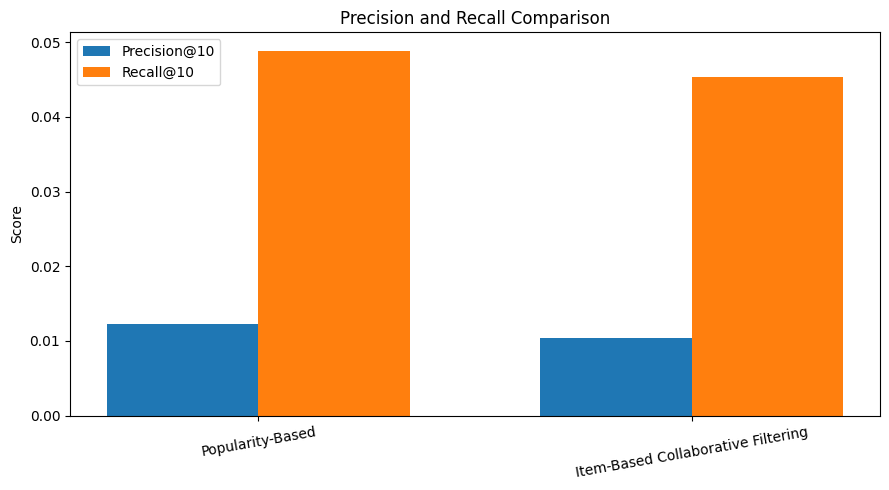

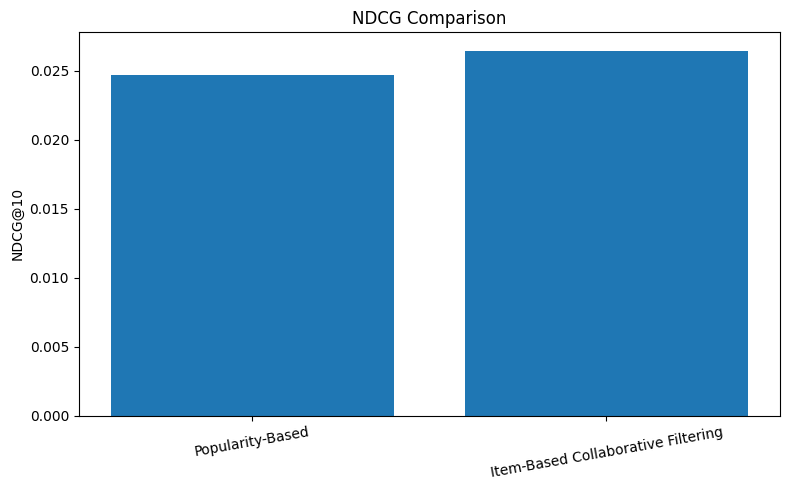

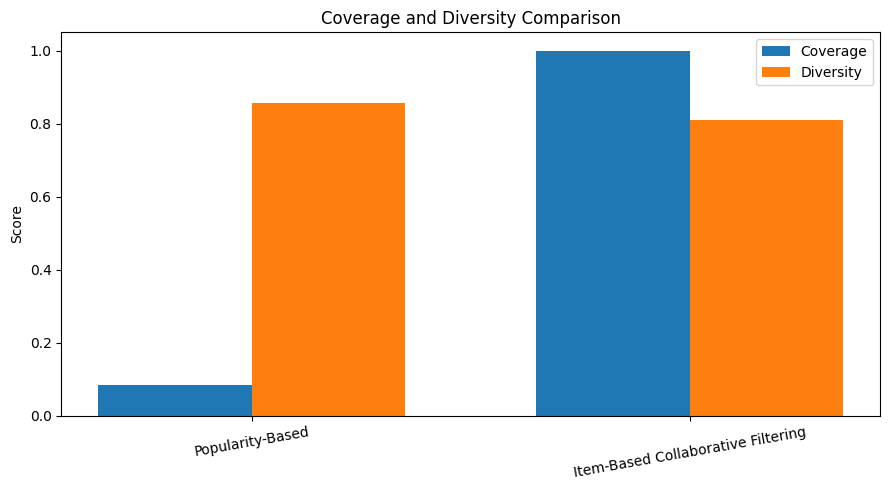

All evaluation charts saved successfully!


In [29]:
# ==========================================
# STEP 7.2: MODEL EVALUATION VISUALIZATION
# ==========================================

import matplotlib.pyplot as plt
import numpy as np

# Model names
models = evaluation_results["Model"].tolist()

# 1. Precision and Recall comparison

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width/2,
    evaluation_results["Precision@10"],
    width,
    label="Precision@10"
)

plt.bar(
    x + width/2,
    evaluation_results["Recall@10"],
    width,
    label="Recall@10"
)

plt.xticks(x, models, rotation=10)
plt.ylabel("Score")
plt.title("Precision and Recall Comparison")
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(project_path, "reports", "precision_recall.png"),
    dpi=300
)

plt.show()


# 2. NDCG comparison

plt.figure(figsize=(8, 5))

plt.bar(
    models,
    evaluation_results["NDCG@10"]
)

plt.ylabel("NDCG@10")
plt.title("NDCG Comparison")
plt.xticks(rotation=10)
plt.tight_layout()

plt.savefig(
    os.path.join(project_path, "reports", "ndcg_comparison.png"),
    dpi=300
)

plt.show()


# 3. Coverage and Diversity comparison

x = np.arange(len(models))

plt.figure(figsize=(9, 5))

plt.bar(
    x - width/2,
    evaluation_results["Coverage"],
    width,
    label="Coverage"
)

plt.bar(
    x + width/2,
    evaluation_results["Diversity"],
    width,
    label="Diversity"
)

plt.xticks(x, models, rotation=10)
plt.ylabel("Score")
plt.title("Coverage and Diversity Comparison")
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(project_path, "reports", "coverage_diversity.png"),
    dpi=300
)

plt.show()

print("All evaluation charts saved successfully!")

In [30]:
# ==========================================
# STEP 8: WORKFLOW ORCHESTRATION
# ==========================================

import os
import pandas as pd
from datetime import datetime

# Define project directories

raw_path = os.path.join(project_path, "data", "raw")
processed_path = os.path.join(project_path, "data", "processed")
features_path = os.path.join(project_path, "data", "features")
models_path = os.path.join(project_path, "models")
reports_path = os.path.join(project_path, "reports")

# Define workflow stages and their dependencies

workflow = [
    {
        "stage": "Data Ingestion",
        "files": [
            "users.csv",
            "items.csv",
            "interactions.csv"
        ],
        "folder": raw_path
    },
    {
        "stage": "Data Validation",
        "files": ["data_validation_report.csv"],
        "folder": reports_path
    },
    {
        "stage": "Data Preparation",
        "files": [
            "users_clean.csv",
            "items_clean.csv",
            "interactions_clean.csv",
            "train_data.csv",
            "test_data.csv"
        ],
        "folder": processed_path
    },
    {
        "stage": "Feature Engineering",
        "files": [
            "user_features.csv",
            "item_features.csv",
            "interaction_features.csv"
        ],
        "folder": features_path
    },
    {
        "stage": "Model Training",
        "files": [
            "popularity_model.csv",
            "item_similarity_matrix.csv",
            "personalized_recommendations_user1.csv"
        ],
        "folder": models_path
    },
    {
        "stage": "Model Evaluation",
        "files": [
            "model_evaluation_results.csv",
            "precision_recall.png",
            "ndcg_comparison.png",
            "coverage_diversity.png"
        ],
        "folder": reports_path
    }
]

# Execute stages in dependency order

workflow_results = []

print("STARTING RECOMMENDATION PIPELINE WORKFLOW")
print("=" * 55)

for stage in workflow:

    missing_files = [
        filename
        for filename in stage["files"]
        if not os.path.exists(
            os.path.join(stage["folder"], filename)
        )
    ]

    if len(missing_files) == 0:
        status = "SUCCESS"
        print(stage["stage"], ":", status)
    else:
        status = "FAILED"
        print(stage["stage"], ":", status)
        print("Missing files:", missing_files)

    workflow_results.append({
        "Stage": stage["stage"],
        "Status": status,
        "Missing Files": ", ".join(missing_files),
        "Execution Time": datetime.now().strftime(
            "%Y-%m-%d %H:%M:%S"
        )
    })

# Save workflow execution log

workflow_log = pd.DataFrame(workflow_results)

workflow_log.to_csv(
    os.path.join(reports_path, "workflow_execution_log.csv"),
    index=False
)

print("=" * 55)

if (workflow_log["Status"] == "SUCCESS").all():
    print("WORKFLOW COMPLETED SUCCESSFULLY!")
else:
    print("WORKFLOW COMPLETED WITH ERRORS.")

print("\nWORKFLOW EXECUTION SUMMARY")
display(workflow_log)

STARTING RECOMMENDATION PIPELINE WORKFLOW
Data Ingestion : SUCCESS
Data Validation : SUCCESS
Data Preparation : SUCCESS
Feature Engineering : SUCCESS
Model Training : SUCCESS
Model Evaluation : SUCCESS
WORKFLOW COMPLETED SUCCESSFULLY!

WORKFLOW EXECUTION SUMMARY


,Stage,Status,Missing Files,Execution Time
0,Data Ingestion,SUCCESS,,2026-11-10 05:56:42
1,Data Validation,SUCCESS,,2026-11-10 05:56:42
2,Data Preparation,SUCCESS,,2026-11-10 05:56:42
3,Feature Engineering,SUCCESS,,2026-11-10 05:56:42
4,Model Training,SUCCESS,,2026-11-10 05:56:42
5,Model Evaluation,SUCCESS,,2026-11-10 05:56:42


In [31]:
# ==========================================
# STEP 9: CREATE PROJECT README
# ==========================================

readme_content = """
# Data Management for Machine Learning – Assignment 2

## End-to-End Data Management Pipeline for a Recommendation System

**Submitted by:** Putta Madhu Rani

**Roll Number:** 2025AG05144

## 1. Project Overview

This project implements an end-to-end data management
pipeline for an e-commerce recommendation system.

The pipeline includes data ingestion, validation,
data preparation, feature engineering, model training,
model evaluation and workflow orchestration.

## 2. Technologies Used

- Python
- Google Colab
- Pandas
- NumPy
- Scikit-learn
- Matplotlib
- Seaborn

## 3. Dataset Description

Synthetic datasets were generated for this project.

| Dataset | Records | Columns |
|---------|---------|---------|
| Users | 500 | 4 |
| Items | 200 | 4 |
| Interactions | 12000 | 6 |

## 4. Pipeline Stages

1. Data Ingestion
2. Data Validation
3. Data Cleaning and Preparation
4. Feature Engineering
5. Train/Test Splitting
6. Recommendation Model Training
7. Model Evaluation
8. Workflow Orchestration

## 5. Recommendation Models

### Model 1: Popularity-Based Recommendation

Recommends products based on their interaction counts.

### Model 2: Item-Based Collaborative Filtering

Uses cosine similarity to generate personalized
recommendations based on user-item ratings.

## 6. Evaluation Results

| Metric | Popularity-Based | Collaborative Filtering |
|--------|------------------|-------------------------|
| Precision@10 | 0.012297 | 0.010441 |
| Recall@10 | 0.048884 | 0.045343 |
| NDCG@10 | 0.024728 | 0.026468 |
| Coverage | 0.085 | 1.000 |
| Diversity | 0.856458 | 0.809126 |

## 7. Conclusion

Both recommendation models were successfully trained
and evaluated.

The popularity-based model achieved higher precision,
recall and diversity.

The item-based collaborative filtering model achieved
higher NDCG and catalog coverage.

The complete workflow executed successfully.

## 8. Author

Putta Madhu Rani

Roll Number: 2025AG05144
"""

readme_path = os.path.join(project_path, "README.md")

with open(readme_path, "w") as file:
    file.write(readme_content)

print("README.md created successfully!")

print("\nREADME location:")
print(readme_path)

README.md created successfully!

README location:
/content/DM4ML_Recommendation_System/README.md


In [32]:
with open(readme_path, "r") as file:
    print(file.read())


# Data Management for Machine Learning – Assignment 2

## End-to-End Data Management Pipeline for a Recommendation System

**Submitted by:** Putta Madhu Rani

**Roll Number:** 2025AG05144

## 1. Project Overview

This project implements an end-to-end data management
pipeline for an e-commerce recommendation system.

The pipeline includes data ingestion, validation,
data preparation, feature engineering, model training,
model evaluation and workflow orchestration.

## 2. Technologies Used

- Python
- Google Colab
- Pandas
- NumPy
- Scikit-learn
- Matplotlib
- Seaborn

## 3. Dataset Description

Synthetic datasets were generated for this project.

| Dataset | Records | Columns |
|---------|---------|---------|
| Users | 500 | 4 |
| Items | 200 | 4 |
| Interactions | 12000 | 6 |

## 4. Pipeline Stages

1. Data Ingestion
2. Data Validation
3. Data Cleaning and Preparation
4. Feature Engineering
5. Train/Test Splitting
6. Recommendation Model Training
7. Model Evaluation
8. Workflow Orches

In [33]:
# ==========================================
# STEP 10: ARCHITECTURE DIAGRAM
# ==========================================

architecture = """
flowchart TD
    A[Raw Data Sources]
    B[Data Ingestion]
    C[Data Validation]
    D[Data Cleaning and Preparation]
    E[Feature Engineering]
    F[Chronological Train/Test Split]
    G[Popularity-Based Model]
    H[Item-Based Collaborative Filtering]
    I[Model Evaluation]
    J[Workflow Orchestration]
    K[Final Reports and Results]

    A --> B
    B --> C
    C --> D
    D --> E
    E --> F
    F --> G
    F --> H
    G --> I
    H --> I
    I --> J
    J --> K
"""

architecture_path = os.path.join(
    project_path, "reports", "architecture_diagram.mmd"
)

with open(architecture_path, "w") as file:
    file.write(architecture)

print("Architecture diagram source created successfully!")
print(architecture)

Architecture diagram source created successfully!

flowchart TD
    A[Raw Data Sources]
    B[Data Ingestion]
    C[Data Validation]
    D[Data Cleaning and Preparation]
    E[Feature Engineering]
    F[Chronological Train/Test Split]
    G[Popularity-Based Model]
    H[Item-Based Collaborative Filtering]
    I[Model Evaluation]
    J[Workflow Orchestration]
    K[Final Reports and Results]

    A --> B
    B --> C
    C --> D
    D --> E
    E --> F
    F --> G
    F --> H
    G --> I
    H --> I
    I --> J
    J --> K



In [34]:
# ==========================================
# STEP 11: CREATE REQUIREMENTS FILE
# ==========================================

requirements = """
pandas
numpy
scikit-learn
matplotlib
seaborn
mlflow
reportlab
"""

requirements_path = os.path.join(
    project_path, "requirements.txt"
)

with open(requirements_path, "w") as file:
    file.write(requirements.strip())

print("requirements.txt created successfully!")

with open(requirements_path, "r") as file:
    print(file.read())

requirements.txt created successfully!
pandas
numpy
scikit-learn
matplotlib
seaborn
mlflow
reportlab


In [36]:
!pip install -q -r /content/DM4ML_Recommendation_System/requirements.txt

print("All project requirements installed successfully!")

All project requirements installed successfully!


In [37]:
# ==========================================
# STEP 12: FINAL PDF REPORT
# ==========================================

import os
import pandas as pd

from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import inch
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer,
    Table, TableStyle, Image, PageBreak
)

# Output PDF path
report_path = os.path.join(
    project_path,
    "reports",
    "DM4ML_Assignment2_Final_Report.pdf"
)

# Create PDF document
doc = SimpleDocTemplate(
    report_path,
    pagesize=A4,
    rightMargin=40,
    leftMargin=40,
    topMargin=40,
    bottomMargin=40
)

styles = getSampleStyleSheet()

title_style = ParagraphStyle(
    "ReportTitle",
    parent=styles["Title"],
    fontSize=18,
    leading=23,
    alignment=TA_CENTER,
    textColor=colors.darkblue,
    spaceAfter=12
)

heading_style = ParagraphStyle(
    "SectionHeading",
    parent=styles["Heading2"],
    fontSize=12,
    leading=15,
    textColor=colors.darkblue,
    spaceBefore=8,
    spaceAfter=6
)

body_style = ParagraphStyle(
    "ReportBody",
    parent=styles["BodyText"],
    fontSize=9,
    leading=13,
    spaceAfter=6
)

story = []

# ==========================================
# PAGE 1: PROJECT INTRODUCTION
# ==========================================

story.append(Paragraph(
    "DATA MANAGEMENT FOR MACHINE LEARNING",
    title_style
))

story.append(Paragraph(
    "Assignment 2: End-to-End Data Management "
    "Pipeline for a Recommendation System",
    ParagraphStyle(
        "Subtitle",
        parent=styles["Heading2"],
        alignment=TA_CENTER,
        fontSize=13
    )
))

story.append(Spacer(1, 15))

student_data = [
    ["Student Name", "Putta Madhu Rani"],
    ["Roll Number", "2025AG05144"],
    ["Project", "E-commerce Recommendation System"],
    ["Environment", "Google Colab"],
    ["Programming Language", "Python"]
]

student_table = Table(student_data, colWidths=[130, 350])

student_table.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (0, -1), colors.lightgrey),
    ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
    ("FONTNAME", (0, 0), (-1, -1), "Helvetica"),
    ("FONTSIZE", (0, 0), (-1, -1), 9),
    ("PADDING", (0, 0), (-1, -1), 7)
]))

story.append(student_table)

story.append(Paragraph("1. Project Objective", heading_style))

story.append(Paragraph(
    "The objective of this project is to design and implement "
    "an end-to-end data management pipeline for an e-commerce "
    "recommendation system. The pipeline covers data ingestion, "
    "validation, cleaning, preparation, feature engineering, "
    "recommendation model training, evaluation and workflow "
    "orchestration.",
    body_style
))

story.append(Paragraph("2. Dataset Description", heading_style))

dataset_table = [
    ["Dataset", "Records", "Columns"],
    ["Users", "500", "4"],
    ["Items", "200", "4"],
    ["Interactions", "12,000", "6"]
]

t = Table(dataset_table, colWidths=[180, 140, 140])
t.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.lightblue),
    ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
    ("ALIGN", (1, 0), (-1, -1), "CENTER"),
    ("PADDING", (0, 0), (-1, -1), 6)
]))
story.append(t)

story.append(Paragraph(
    "Synthetic data was generated for 500 users, 200 products "
    "and 12,000 user-item interactions. The interaction records "
    "contain ratings, interaction types and timestamps.",
    body_style
))

story.append(Paragraph("3. Data Validation and Preparation", heading_style))

story.append(Paragraph(
    "The datasets were checked for missing values, duplicate "
    "records, invalid ratings, invalid interaction types, "
    "invalid user and item references, invalid timestamps "
    "and invalid item prices. All 12 validation checks passed "
    "with zero invalid records. The cleaned datasets preserved "
    "all 500 users, 200 items and 12,000 interactions. "
    "An 80:20 chronological split produced 9,600 training "
    "records and 2,400 testing records.",
    body_style
))

story.append(PageBreak())

# ==========================================
# PAGE 2: FEATURES AND MODELS
# ==========================================

story.append(Paragraph(
    "4. Feature Engineering",
    heading_style
))

story.append(Paragraph(
    "User features include interaction count, average rating "
    "and preferred category. Item features include interaction "
    "count, average rating and popularity score. Interaction "
    "features include days since interaction and product category. "
    "The feature catalog was saved as a CSV file.",
    body_style
))

story.append(Paragraph(
    "5. Recommendation Models",
    heading_style
))

story.append(Paragraph(
    "<b>Model 1 – Popularity-Based Recommendation:</b> "
    "Ranks products according to their interaction counts "
    "in the training dataset and recommends globally popular "
    "products.",
    body_style
))

story.append(Paragraph(
    "<b>Model 2 – Item-Based Collaborative Filtering:</b> "
    "Uses a user-item rating matrix and cosine similarity "
    "between items to generate personalized recommendations.",
    body_style
))

story.append(Paragraph(
    "6. Model Evaluation",
    heading_style
))

evaluation_table = [
    ["Metric", "Popularity", "Collaborative Filtering"],
    ["Precision@10", "0.012297", "0.010441"],
    ["Recall@10", "0.048884", "0.045343"],
    ["NDCG@10", "0.024728", "0.026468"],
    ["Coverage", "0.085", "1.000"],
    ["Diversity", "0.856458", "0.809126"]
]

t = Table(
    evaluation_table,
    colWidths=[125, 140, 195]
)

t.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.lightblue),
    ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
    ("ALIGN", (1, 1), (-1, -1), "CENTER"),
    ("FONTSIZE", (0, 0), (-1, -1), 8),
    ("PADDING", (0, 0), (-1, -1), 6)
]))

story.append(t)

story.append(Spacer(1, 8))

story.append(Paragraph(
    "Evaluation used test interactions with ratings of 4 or 5 "
    "as relevant items. Both models were evaluated using the "
    "same 431 eligible users and top-10 recommendations.",
    body_style
))

# Add evaluation charts
story.append(Paragraph(
    "7. Evaluation Visualizations",
    heading_style
))

chart_paths = [
    os.path.join(project_path, "reports", "precision_recall.png"),
    os.path.join(project_path, "reports", "ndcg_comparison.png"),
    os.path.join(project_path, "reports", "coverage_diversity.png")
]

for chart_path in chart_paths:
    if os.path.exists(chart_path):
        story.append(
            Image(chart_path, width=220, height=125)
        )
        story.append(Spacer(1, 5))

story.append(PageBreak())

# ==========================================
# PAGE 3: ORCHESTRATION AND CONCLUSION
# ==========================================

story.append(Paragraph(
    "8. Workflow Orchestration",
    heading_style
))

story.append(Paragraph(
    "A dependency-ordered Python workflow was developed to "
    "verify the output files of each pipeline stage. The "
    "workflow checked data ingestion, validation, preparation, "
    "feature engineering, model training and model evaluation. "
    "All six stages reported SUCCESS, with no missing files.",
    body_style
))

# Architecture diagram description
story.append(Paragraph(
    "9. System Architecture",
    heading_style
))

architecture_text = (
    "Raw Data Sources → Data Ingestion → Data Validation → "
    "Data Cleaning and Preparation → Feature Engineering → "
    "Chronological Train/Test Split → "
    "Popularity-Based Model and Collaborative Filtering → "
    "Model Evaluation → Workflow Orchestration → Final Reports"
)

story.append(Paragraph(architecture_text, body_style))

story.append(Paragraph(
    "10. Results and Discussion",
    heading_style
))

story.append(Paragraph(
    "The popularity-based model achieved higher Precision@10, "
    "Recall@10 and Diversity. The collaborative filtering model "
    "achieved higher NDCG@10 and full catalog coverage. "
    "Therefore, neither model was best across every metric. "
    "The experiment uses synthetic data, so the measured scores "
    "should be interpreted as results of this demonstration "
    "rather than evidence of real-world recommendation quality.",
    body_style
))

story.append(Paragraph(
    "11. Conclusion",
    heading_style
))

story.append(Paragraph(
    "An end-to-end data management pipeline for an e-commerce "
    "recommendation system was implemented successfully. "
    "The project demonstrated data ingestion, validation, "
    "preparation, feature engineering, chronological data "
    "splitting, two recommendation approaches, model evaluation "
    "and workflow execution. All six workflow verification "
    "stages completed successfully.",
    body_style
))

story.append(Spacer(1, 15))

story.append(Paragraph(
    "<b>Submitted by: Putta Madhu Rani</b><br/>"
    "<b>Roll Number: 2025AG05144</b>",
    body_style
))

# Generate PDF
doc.build(story)

print("FINAL PDF REPORT CREATED SUCCESSFULLY!")
print("Location:", report_path)
print("File size:", round(os.path.getsize(report_path) / 1024, 2), "KB")

FINAL PDF REPORT CREATED SUCCESSFULLY!
Location: /content/DM4ML_Recommendation_System/reports/DM4ML_Assignment2_Final_Report.pdf
File size: 394.47 KB


In [38]:
import os

print("PDF exists:", os.path.exists(report_path))

if os.path.exists(report_path):
    print("PDF size:", round(
        os.path.getsize(report_path) / 1024, 2
    ), "KB")

    print("\nReport files:")
    print(os.listdir(os.path.join(project_path, "reports")))

PDF exists: True
PDF size: 394.47 KB

Report files:
['model_evaluation_results.csv', 'precision_recall.png', 'data_validation_report.csv', 'feature_catalog.csv', 'DM4ML_Assignment2_Final_Report.pdf', 'architecture_diagram.mmd', 'coverage_diversity.png', 'ndcg_comparison.png', 'workflow_execution_log.csv', 'model_comparison.csv']


In [39]:
# ==========================================
# FINAL PDF VALIDATION
# ==========================================

!pip install -q pypdf

import os
from pypdf import PdfReader

# PDF location
report_path = os.path.join(
    project_path,
    "reports",
    "DM4ML_Assignment2_Final_Report.pdf"
)

# Check file existence
assert os.path.exists(report_path), "PDF file not found!"

# Open PDF
reader = PdfReader(report_path)

# Extract text
pdf_text = "\n".join(
    page.extract_text() or ""
    for page in reader.pages
)

# Required content checks
required_content = [
    "Putta Madhu Rani",
    "2025AG05144",
    "Project Objective",
    "Dataset Description",
    "Feature Engineering",
    "Popularity-Based",
    "Collaborative Filtering",
    "Precision@10",
    "Recall@10",
    "NDCG@10",
    "Coverage",
    "Diversity",
    "Workflow Orchestration",
    "Conclusion"
]

print("FINAL PDF VALIDATION REPORT")
print("=" * 45)

print("PDF exists:", os.path.exists(report_path))
print("PDF opens successfully:", not reader.is_encrypted)
print("Number of pages:", len(reader.pages))

print("\nCONTENT VALIDATION")

for item in required_content:
    status = "PASS" if item.lower() in pdf_text.lower() else "FAIL"
    print(item, ":", status)

# Check evaluation values
print("\nEVALUATION VALUE CHECK")

for value in [
    "0.012297",
    "0.010441",
    "0.048884",
    "0.045343",
    "0.026468",
    "0.856458",
    "0.809126"
]:
    print(value, ":", "PASS" if value in pdf_text else "FAIL")

# File size
print("\nPDF SIZE:",
      round(os.path.getsize(report_path) / 1024, 2), "KB")

print("\nPDF VALIDATION COMPLETED!")

FINAL PDF VALIDATION REPORT
PDF exists: True
PDF opens successfully: True
Number of pages: 3

CONTENT VALIDATION
Putta Madhu Rani : PASS
2025AG05144 : PASS
Project Objective : PASS
Dataset Description : PASS
Feature Engineering : PASS
Popularity-Based : PASS
Collaborative Filtering : PASS
Precision@10 : PASS
Recall@10 : PASS
NDCG@10 : PASS
Coverage : PASS
Diversity : PASS
Workflow Orchestration : PASS
Conclusion : PASS

EVALUATION VALUE CHECK
0.012297 : PASS
0.010441 : PASS
0.048884 : PASS
0.045343 : PASS
0.026468 : PASS
0.856458 : PASS
0.809126 : PASS

PDF SIZE: 394.47 KB

PDF VALIDATION COMPLETED!


In [40]:
# ==========================================
# PREPARE PROJECT FOR GITHUB
# ==========================================

import shutil
import os

zip_path = shutil.make_archive(
    "/content/DM4ML_Assignment2_Recommendation_System",
    "zip",
    root_dir="/content",
    base_dir="DM4ML_Recommendation_System"
)

print("Project ZIP created successfully!")
print("Location:", zip_path)

print("File size:",
      round(os.path.getsize(zip_path) / (1024 * 1024), 2),
      "MB")

from google.colab import files
files.download(zip_path)

Project ZIP created successfully!
Location: /content/DM4ML_Assignment2_Recommendation_System.zip
File size: 1.36 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>